In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)

sns.set_theme()
RANDOM_STATE = 42

data, meta = arff.loadarff("../data/Training Dataset.arff")
df = pd.DataFrame(data)
df = df.apply(lambda col: col.str.decode("utf-8") if col.dtype == object else col)
df = df.astype(int)
print("Original shape:", df.shape)

Original shape: (11055, 31)


In [2]:
df = df.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", df.shape)
print(df["Result"].value_counts())
print(df["Result"].value_counts(normalize=True))

After removing duplicates: (5849, 31)
Result
-1    3019
 1    2830
Name: count, dtype: int64
Result
-1    0.516157
 1    0.483843
Name: proportion, dtype: float64


In [3]:
X = df.drop(columns="Result")
y = df["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Train: (4679, 30) Test: (1170, 30)
Result
-1    0.516136
 1    0.483864
Name: proportion, dtype: float64
Result
-1    0.516239
 1    0.483761
Name: proportion, dtype: float64


                precision    recall  f1-score   support

 phishing (-1)       0.93      0.90      0.91       604
legitimate (1)       0.90      0.92      0.91       566

      accuracy                           0.91      1170
     macro avg       0.91      0.91      0.91      1170
  weighted avg       0.91      0.91      0.91      1170

ROC-AUC: 0.9737936723375377


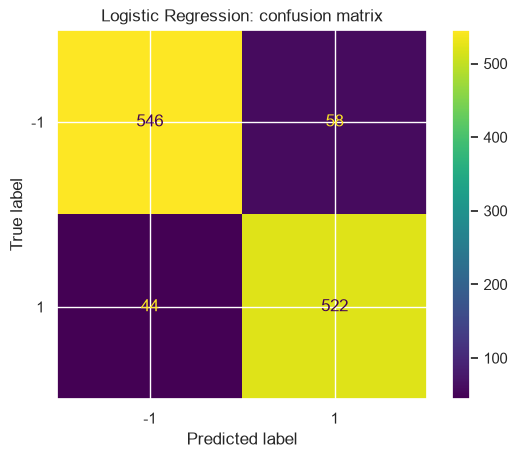

In [4]:
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["phishing (-1)", "legitimate (1)"]))
print("ROC-AUC:", roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Logistic Regression: confusion matrix")
plt.savefig("../reports/cm_logreg.png", dpi=150)
plt.show()

## Preprocessing and Baseline Model

### Preprocessing
- **Original data:** 11,055 rows, 31 columns.
- **Duplicates removed:** 5,206 duplicate rows were dropped before splitting to avoid data leakage between the training and test sets. This left **5,849 rows**.
- **Class balance after deduplication:** 3,019 phishing (51.6%) and 2,830 legitimate (48.4%). The classes are now close to balanced, so the majority class has changed compared with the raw data (55.7% legitimate).
- **Train/test split:** 80/20 stratified split with `random_state=42`, giving 4,679 training and 1,170 test samples. Class proportions are preserved in both sets.
- **Scaling:** Not applied, because all features are discrete values in {-1, 0, 1}.

### Baseline: Logistic Regression
| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| Phishing (-1) | 0.93 | 0.90 | 0.91 | 604 |
| Legitimate (1) | 0.90 | 0.92 | 0.91 | 566 |

- **Accuracy:** 0.91
- **ROC-AUC:** 0.974

### Confusion matrix (test set)
| | Predicted phishing | Predicted legitimate |
|---|---|---|
| **Actual phishing** | 546 (TP) | 58 (FN) |
| **Actual legitimate** | 44 (FP) | 522 (TN) |

### Interpretation
- The baseline performs well, with high ROC-AUC, but it is not perfect.
- **False negatives (58, about 9.6% of phishing sites)** are the most serious error: a phishing site is treated as safe and a user could be harmed.
- **False positives (44, about 7.8% of legitimate sites)** block safe sites, which costs user trust and productivity.
- Scores are lower than those often reported on the raw, duplicated dataset, which supports the decision to remove duplicates first.
- Next steps: compare tree-based models, tune hyperparameters with cross-validation, and examine the threshold trade-off between false negatives and false positives.

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import precision_score, recall_score, f1_score

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "F1 std": scores["test_f1"].std(),
    })

cv_results = pd.DataFrame(cv_rows).set_index("Model").round(3)
cv_results

,Accuracy,Precision,Recall,F1,ROC-AUC,F1 std
Model,,,,,,
Logistic Regression,0.922,0.912,0.928,0.920,0.976,0.013
Decision Tree,0.918,0.918,0.913,0.915,0.923,0.010
Random Forest,0.944,0.938,0.947,0.942,0.989,0.008
Gradient Boosting,0.944,0.936,0.948,0.942,0.989,0.009


In [9]:
test_rows = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[1, -1]).ravel()
    # labels=[1, -1] makes "phishing (-1)" the positive class in this table
    test_rows.append({
        "Model": name,
        "Accuracy": (pred == y_test).mean(),
        "Phishing precision": precision_score(y_test, pred, pos_label=-1),
        "Phishing recall": recall_score(y_test, pred, pos_label=-1),
        "Phishing F1": f1_score(y_test, pred, pos_label=-1),
        "ROC-AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
        "False negatives": fn,   # phishing predicted legitimate
        "False positives": fp,   # legitimate predicted phishing
    })

test_results = pd.DataFrame(test_rows).set_index("Model").round(3)
test_results

,Accuracy,Phishing precision,Phishing recall,Phishing F1,ROC-AUC,False negatives,False positives
Model,,,,,,,
Logistic Regression,0.913,0.925,0.904,0.915,0.974,58,44
Decision Tree,0.917,0.916,0.924,0.920,0.922,46,51
Random Forest,0.943,0.951,0.937,0.944,0.988,38,29
Gradient Boosting,0.946,0.955,0.940,0.947,0.989,36,27


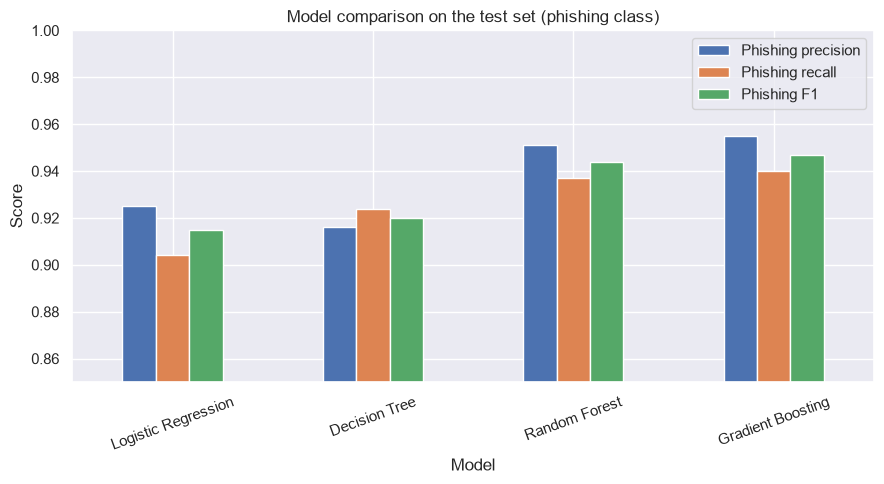

In [10]:
test_results[["Phishing precision", "Phishing recall", "Phishing F1"]].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Model comparison on the test set (phishing class)")
plt.ylabel("Score")
plt.ylim(0.85, 1.0)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../reports/model_comparison.png", dpi=150)
plt.show()

## Model Comparison

Four models were compared using 5-fold stratified cross-validation on the training set, then evaluated once on the held-out test set. In the cross-validation table, precision and recall refer to the legitimate class (scikit-learn's default positive label). In the test-set table, the phishing class is treated as positive.

### Cross-validation (training set)
| Model | Accuracy | F1 | ROC-AUC | F1 std |
|---|---|---|---|---|
| Logistic Regression | 0.922 | 0.920 | 0.976 | 0.013 |
| Decision Tree | 0.918 | 0.915 | 0.923 | 0.010 |
| Random Forest | 0.944 | 0.942 | 0.989 | 0.008 |
| Gradient Boosting | 0.944 | 0.942 | 0.989 | 0.009 |

### Test set (phishing class as positive)
| Model | Accuracy | Phishing precision | Phishing recall | Phishing F1 | False negatives | False positives |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.913 | 0.925 | 0.904 | 0.915 | 58 | 44 |
| Decision Tree | 0.917 | 0.916 | 0.924 | 0.920 | 46 | 51 |
| Random Forest | 0.943 | 0.951 | 0.937 | 0.944 | 38 | 29 |
| Gradient Boosting | 0.946 | 0.955 | 0.940 | 0.947 | 36 | 27 |

### Interpretation
- The two ensemble models outperform Logistic Regression and the Decision Tree on every metric, by a margin larger than the cross-validation standard deviation.
- Random Forest and Gradient Boosting are statistically indistinguishable here: identical CV scores, and a 2-sample difference in false negatives on the test set.
- Gradient Boosting reduced missed phishing sites from 58 (baseline) to 36, while also reducing false positives from 44 to 27.
- The Decision Tree's CV and test scores are similar, so there is no evidence of overfitting at the default settings. Training scores were not measured.
- Results come from a single test split of 1,170 samples, so small differences should be treated with caution.
- A coding error in the false-negative/false-positive labels was found when the table was checked against the baseline confusion matrix and recall values, and was corrected.